# Atlas-guided cell typing of Visium HD at 2 µm

## Motivation

Visium HD captures transcripts on a grid of 2 µm bins, well below the size of a cell. A single bin holds only a
handful of transcripts, too few to cluster or to annotate on its own, and a cell covers many bins. One way out is
to sum the bins to 8 or 16 µm, but then thin cells such as capillary endothelium and pericytes disappear into the
cardiomyocytes around them. We keep the 2 µm resolution and use the snRNA atlas of the heart as a guide instead:
FICTURE decodes every pixel as a mixture of the atlas cell types, borrowing strength from the neighbouring pixels.

A decode alone is not yet a cell-type map. Three questions remain, and they are the subject of this notebook: how
certain is the call of a bin, which bins can be trusted for rare cell types, and which bins hold transcripts that
did not come from a cell at this position at all. Transcripts of cardiomyocytes, smooth muscle and vessel
endothelium diffuse into the empty space next to their cells; we find these bins on the registered H&E image and
remove them (CMFLAG). The result, the 2 µm and 8 µm `AnnData` objects of every section, is what all other
Visium HD analyses start from.

## Dataset

We work with 11 Visium HD sections of the human left ventricle: eight sections from Berlin and three AH sections.
For every section we have the Space Ranger output and an H&E image of the same section from a microscope. The
cell types come from the HHCA snRNA atlas at Level 3 of its annotation (23 types).

| object | content | fields used here |
|---|---|---|
| atlas model (`atlas_L3_pseudobulk.tsv`) | genes × 23 Level-3 types, mean expression | all |
| FICTURE pixel decode (`.pixel.tsv.gz`) | one row per decode pixel | `X`, `Y` (µm), `K1`–`K5` (codes of the five most probable types), `P1`–`P5` (their probabilities) |
| FICTURE inputs (`transcripts.tsv.gz`) | one row per transcript position | `X`, `Y`, `gene`, `Count` |
| Space Ranger bins (`square_002um`, `square_008um`) | bins × features, raw counts | counts, bin positions |
| microscopy H&E and its registration | image of the section, affine map from µm to image pixels | `M0`, `t0` |

Three steps are too heavy for a notebook and are run by the pipeline: building the atlas model, the FICTURE decode
(a few hours per section) and the registration of the H&E image. We describe them where they enter and load their
results. Everything else is computed here on one section, with the functions of `hhca.tl` that the scripts in
`scripts/substrate/` call on all sections.

## Environment setup

We load the packages and set the scanpy defaults; `style.notebook()` gives the plots of this notebook the font and
open axes of the figure panels. All paths in the configuration are relative to the repository
root, so we work from there.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import json
import os

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import tifffile
from PIL import Image

import hhca
from hhca.config import fill, load_config, resolve_roots, section_path
from hhca.grid import SPILLOVER_FLAGS
from hhca.pl import style

sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)
style.notebook()
np.random.seed(0)
os.chdir(hhca.REPO)

The parameters of the cell typing are set in `config/substrate.yaml`, those of the spillover flags in
`config/substrate_cmflag.yaml`. We read both files once and keep the blocks we use most under short names: the
certainty score, the thresholds per type and the fields shown in this notebook. The table lists the sections with
their site and their position in the wall.

In [2]:
cfg = load_config("substrate")
cmflag = load_config("substrate_cmflag")
certainty_cfg = cfg["certainty"]
tau_cfg = cfg["tau"]
notebook_cfg = cfg["notebook"]
all_sections = list(cfg["slides"])
scored_sections = certainty_cfg["slides"]
pd.DataFrame(cfg["slides"]).T[["site", "region"]]

,site,region
VS_BO_HDZ150319_34_myo,berlin,myo
VS_BO_2024BH-008_myo,berlin,myo
VS_CA_H0054LV_henricke_endo,berlin,endo
VS_CA_H0054LV_henricke_epi,berlin,epi
VS_CA_H0054LV_henricke_myo,berlin,myo
VS_CA_H0063LV_henricke_endo,berlin,endo
VS_CA_H0063LV_henricke_epi,berlin,epi
VS_CA_H0063LV_henricke_myo,berlin,myo
VS_AH9_LV_FW_epi,ah,epi
VS_AH10_LV_mid_endo,ah,endo


## Loading data

We walk through each step on one section, `VS_CA_H0054LV_henricke_endo`, the endocardial section of donor H0054,
and look at all 11 sections at the end.

### The atlas model

FICTURE needs to know what each cell type looks like. The model is a matrix with the mean expression of every
gene in each Level-3 type of the atlas: the counts of each nucleus are scaled to 10,000, the nuclei are averaged
per type, and the genes are restricted to those detected on Visium HD. The pipeline builds it once from the
atlas nuclei that have a Level-3 type:

```bash
sbatch workflow/hpc/substrate_model.sbatch
```

In [3]:
section = "VS_CA_H0054LV_henricke_endo"
with open(section_path(cfg, "factor_order")) as handle:
    factor_order = json.load(handle)

model = pd.read_csv(section_path(cfg, "model"), sep="\t", index_col=0)[factor_order]
nuclei = pd.read_csv(section_path(cfg, "nuclei"), index_col="factor")["n_cells"]
n_genes, n_types = model.shape
n_nuclei = nuclei.sum()
print(f"{n_genes:,} genes x {n_types} types, built from {n_nuclei:,} nuclei")
model.iloc[:5, :4].round(3)

14,016 genes x 23 types, built from 1,388,857 nuclei


,Adipocytes,Arterial Endothelial cells,Atrial Cardiomyocytes,B cells
gene,,,,
A2M,0.180,8.703,1.410,0.212
A3GALT2,0.029,0.012,0.014,0.004
A4GALT,0.143,0.628,0.726,0.002
AAAS,0.291,0.092,0.269,0.212
AACS,2.672,0.055,0.247,0.263


### The FICTURE decode

With this model fixed, FICTURE assigns every pixel of a section to the cell types. The model is not refitted to
the section, so a factor keeps the meaning of its atlas type on every section. The decode of the 11 sections is
an array job of the pipeline:

```bash
sbatch --array=0-10 workflow/hpc/substrate_decode.sbatch
```

The result is a table with one row per decode pixel: its position in µm, the five most probable types (`K1` to
`K5`, as positions in the list of types) and their probabilities.

In [4]:
top_k = 5  # FICTURE writes the five most probable types of every pixel
factor_columns = [f"K{rank}" for rank in range(1, top_k + 1)]
posterior_columns = [f"P{rank}" for rank in range(1, top_k + 1)]
decode = pd.read_csv(
    section_path(cfg, "decode", section), sep="\t", usecols=["X", "Y", *factor_columns, *posterior_columns]
)
print(f"{len(decode):,} decode pixels")
decode.head()

9,030,539 decode pixels


,X,Y,K1,K2,K3,K4,K5,P1,P2,P3,P4,P5
0,7471.1,4638.1,22,8,17,9,10,1.0,2.190000e-12,2.870000e-20,1.230000e-23,2.080000e-25
1,7472.6,4274.3,22,17,8,9,18,1.0,1.390000e-10,1.190000e-20,1.450000e-21,1.040000e-26
2,7472.6,4280.3,22,17,10,9,18,1.0,1.590000e-17,3.690000e-18,2.610000e-22,9.390000e-35
3,7472.7,4342.2,22,17,18,9,4,1.0,3.250000e-12,4.940000e-22,2.770000e-23,2.920000e-30
4,7472.8,4418.2,22,4,10,18,17,1.0,5.880000e-12,9.890000e-15,3.600000e-16,2.190000e-17


### The Space Ranger bins

The decode holds the calls but no expression. The counts come from the 2 µm bins of Space Ranger, which
`hhca.tl.read_bins` reads as an `AnnData` with the bin centres in µm in `obsm["spatial"]`.

In [5]:
bins = hhca.tl.read_bins(section_path(cfg, "square_002um", section))
bins

AnnData object with n_obs × n_vars = 8156242 × 18085
    obs: 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'microns_per_pixel'
    obsm: 'spatial'

## What does the model know about each cell type?

Before we look at the decode, we look at the model itself. `hhca.tl.model_markers` picks marker genes for every
type: genes that are at least 1.5 times higher than the mean of the other types and lie in the upper 30% of the
type's profile, ranked by enrichment and expression. We will need these markers below to ask whether a bin that
is called a fibroblast also holds fibroblast transcripts.

In [6]:
markers_cfg = certainty_cfg["markers"]
markers = hhca.tl.model_markers(
    model,
    top_n=markers_cfg["top_n"],
    min_enrichment=markers_cfg["min_enrichment"],
    expression_quantile=markers_cfg["expression_quantile"],
)
top_markers = {cell_type: genes[:3] for cell_type, genes in markers.items()}
n_markers = pd.Series(markers).str.len()
first_three = pd.Series(top_markers).str.join(", ")
pd.DataFrame({"nuclei": nuclei, "markers": n_markers, "first three": first_three})

,nuclei,markers,first three
Adipocytes,12538,24,"GPAM, ACACB, MGST1"
Arterial Endothelial cells,20583,24,"MECOM, PIK3R3, PTPRB"
Atrial Cardiomyocytes,121186,24,"RYR2, FGF12, MYL7"
B cells,839,24,"AFF3, RALGPS2, CD74"
Capillary Endothelial cells,69364,24,"VWF, ANO2, FLT1"
Dendritic cells,3385,24,"RTN1, CIITA, CPVL"
Endocardial Endothelial Cells,70018,24,"PCDH7, ADAMTSL1, POSTN"
Epicardium,20865,24,"KCNT2, C3, PRG4"
Fibroblasts,321283,24,"DCN, LAMA2, NEGR1"
ILC,72,24,"IL7R, AFF3, RUNX2"


For a view of the whole model we put it into an `AnnData` with one observation per type, take the logarithm,
z-score every gene across the types and plot the first three markers of each type.

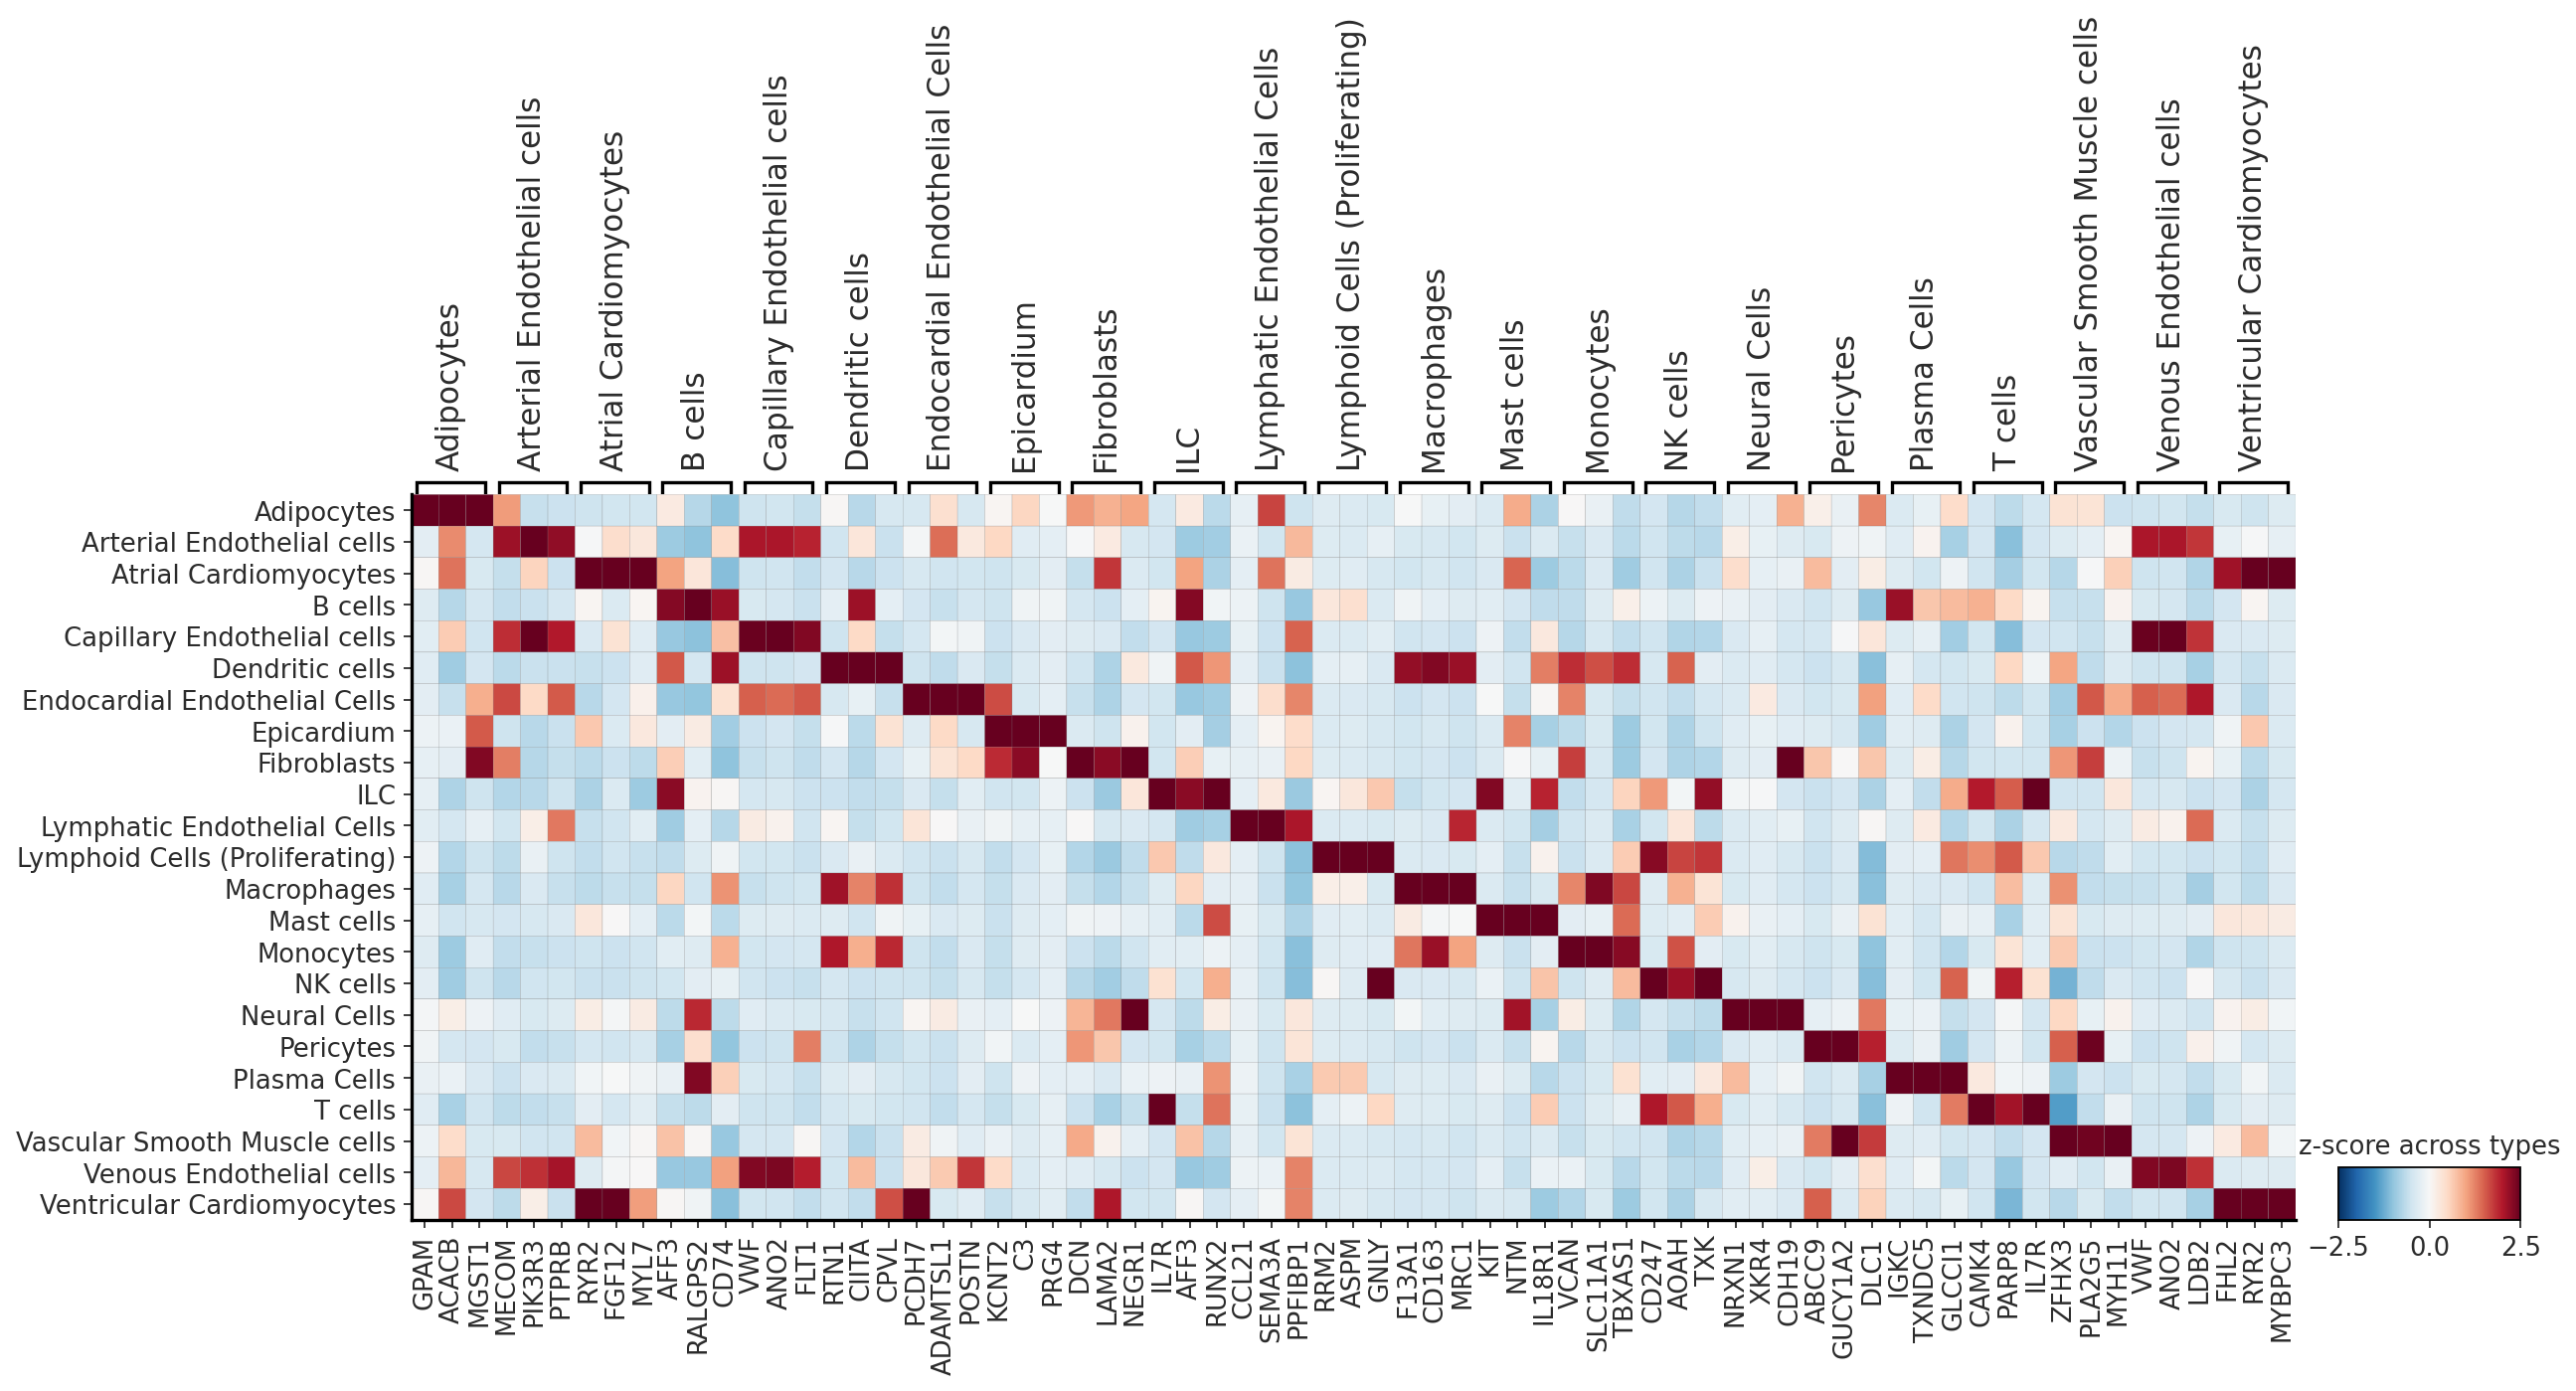

In [7]:
profiles = ad.AnnData(model.T.astype("float32"))
profiles.obs["cell type"] = pd.Categorical(profiles.obs_names, categories=factor_order)
sc.pp.log1p(profiles)
sc.pp.scale(profiles)
sc.pl.matrixplot(
    profiles,
    top_markers,
    groupby="cell type",
    cmap=style.DIVERGING,
    vmin=-2.5,
    vmax=2.5,
    colorbar_title="z-score across types",
    figsize=(17, 6),
)

The model holds 14,016 genes for 23 types and rests on 1,388,857 nuclei; the rarest types are built from few
of them (72 ILC, 440 plasma cells). Every type gets 24 markers, and the first ones are the expected genes: *DCN*
for fibroblasts, *F13A1*, *CD163* and *MRC1* for macrophages, *NRXN1* and *CDH19* for neural cells. Related types
share markers: *VWF* and *ANO2* lead for both capillary and venous endothelium.

## From decode pixels to calls

How decisive is the decode? We look at the most probable type of every pixel and at its probability.

In [8]:
decisive_posterior = 0.99  # a call with a higher posterior counts as decisive
top_type = pd.Categorical.from_codes(decode["K1"], categories=factor_order)
decisive = decode["P1"] > decisive_posterior
calls = pd.DataFrame(
    {
        "pixels": pd.Series(top_type).value_counts(),
        "median P1": decode["P1"].groupby(top_type, observed=False).median(),
        f"P1 > {decisive_posterior} (%)": 100 * decisive.groupby(top_type, observed=False).mean(),
    }
)
calls["% of pixels"] = 100 * calls["pixels"] / len(decode)
share_decisive = decisive.mean()
print(f"{share_decisive:.1%} of all pixels have P1 > {decisive_posterior}")
calls.sort_values("pixels", ascending=False).round(2)

98.9% of all pixels have P1 > 0.99


,pixels,median P1,P1 > 0.99 (%),% of pixels
Ventricular Cardiomyocytes,8542782,1.00,99.62,94.60
Fibroblasts,168267,1.00,86.36,1.86
Capillary Endothelial cells,101278,1.00,86.53,1.12
Pericytes,72361,1.00,83.94,0.80
Vascular Smooth Muscle cells,58933,1.00,93.85,0.65
Macrophages,32013,1.00,89.86,0.35
Arterial Endothelial cells,15455,1.00,92.51,0.17
Neural Cells,10091,1.00,90.31,0.11
Venous Endothelial cells,7875,1.00,91.97,0.09
Lymphatic Endothelial Cells,7207,1.00,79.08,0.08


The decode is decisive: 98.9% of the 9,030,539 pixels have a posterior above 0.99, and the median posterior is
1.00 for every type. Ventricular cardiomyocytes take 94.60% of the pixels, fibroblasts 1.86% and capillary
endothelium 1.12%. A posterior this close to 1 almost everywhere cannot tell us which calls to trust.

## A certainty score for every pixel

Since the posterior does not separate good calls from poor ones, we describe every decode pixel by four
quantities that do not come from the model fit. `hhca.tl.certainty_components` places the pixels and the
transcripts on the 2 µm grid of the section and returns them:

- `margin`: the posterior of the best type minus that of the second,
- `depth_raw`: how many transcripts and how many different genes the 3 × 3 neighbourhood holds,
- `marker_raw`: the share of the transcripts in the neighbourhood that are markers of the called type,
- `spatial_raw`: the share of the eight neighbours with the same call.

The function reads all transcripts of the section, which takes about three minutes.

In [9]:
components = hhca.tl.certainty_components(
    decode, section_path(cfg, "inputs", section), markers, chunksize=certainty_cfg["chunksize"]
)
components.describe().loc[["mean", "25%", "50%", "75%"]].round(3)

,margin,depth_raw,marker_raw,spatial_raw,marker_support,local_umi,local_gene_est
mean,0.998,4.718,0.057,0.948,0.978,130.097,125.670
25%,1.000,4.420,0.038,1.000,1.000,83.000,81.005
50%,1.000,4.778,0.054,1.000,1.000,119.000,115.671
75%,1.000,5.095,0.073,1.000,1.000,165.000,158.644


The score is defined on the eight Berlin sections; the three AH sections carry none.
`scripts/substrate/build_certainty_score.py` computes the components of every pixel of the eight sections,
together with its call and marker support; for the score we load the tables it writes (`features`).

The four components live on different scales. To combine them, each one is scaled to the range 0 to 1 between its
5th and its 95th percentile. The percentiles are taken once over a random sample of 180,000 pixels from each of
the eight sections (`hhca.tl.sample_rows`, `hhca.tl.component_quantiles`), so that a score means the same on every
section.

In [10]:
features = {name: np.load(section_path(cfg, "checkpoint", name)) for name in scored_sections}
low_quantile, high_quantile = certainty_cfg["quantiles"]
sample = hhca.tl.sample_rows(
    features, n_per_section=certainty_cfg["sample_per_slide"], seed=certainty_cfg["sampling_seed"]
)
quantiles = hhca.tl.component_quantiles(sample, low=low_quantile, high=high_quantile)
pd.DataFrame(quantiles, index=["5th percentile", "95th percentile"]).T

,5th percentile,95th percentile
margin,0.999911,1.000000
depth_raw,3.792162,5.511970
marker_raw,0.016393,0.107143
spatial_raw,0.750000,1.000000


`hhca.tl.certainty_score` is the weighted sum of the scaled components. Depth and marker share carry most of the
weight (0.35 and 0.30), the agreement with the neighbours 0.20 and the posterior margin 0.15.

In [11]:
score_weights = certainty_cfg["weights"]
decode["certainty"] = hhca.tl.certainty_score(components, quantiles, score_weights)
print(pd.Series(score_weights).to_string())
score_summary = decode["certainty"].describe().loc[["mean", "25%", "50%", "75%"]]
score_summary.round(3).to_frame().T

posterior    0.15
depth        0.35
marker       0.30
spatial      0.20


,mean,25%,50%,75%
certainty,0.64,0.549,0.663,0.754


Let's look at the components and the score in a 340 µm field around a vessel; its centre and size are set in the
`notebook` block of `config/substrate.yaml`.

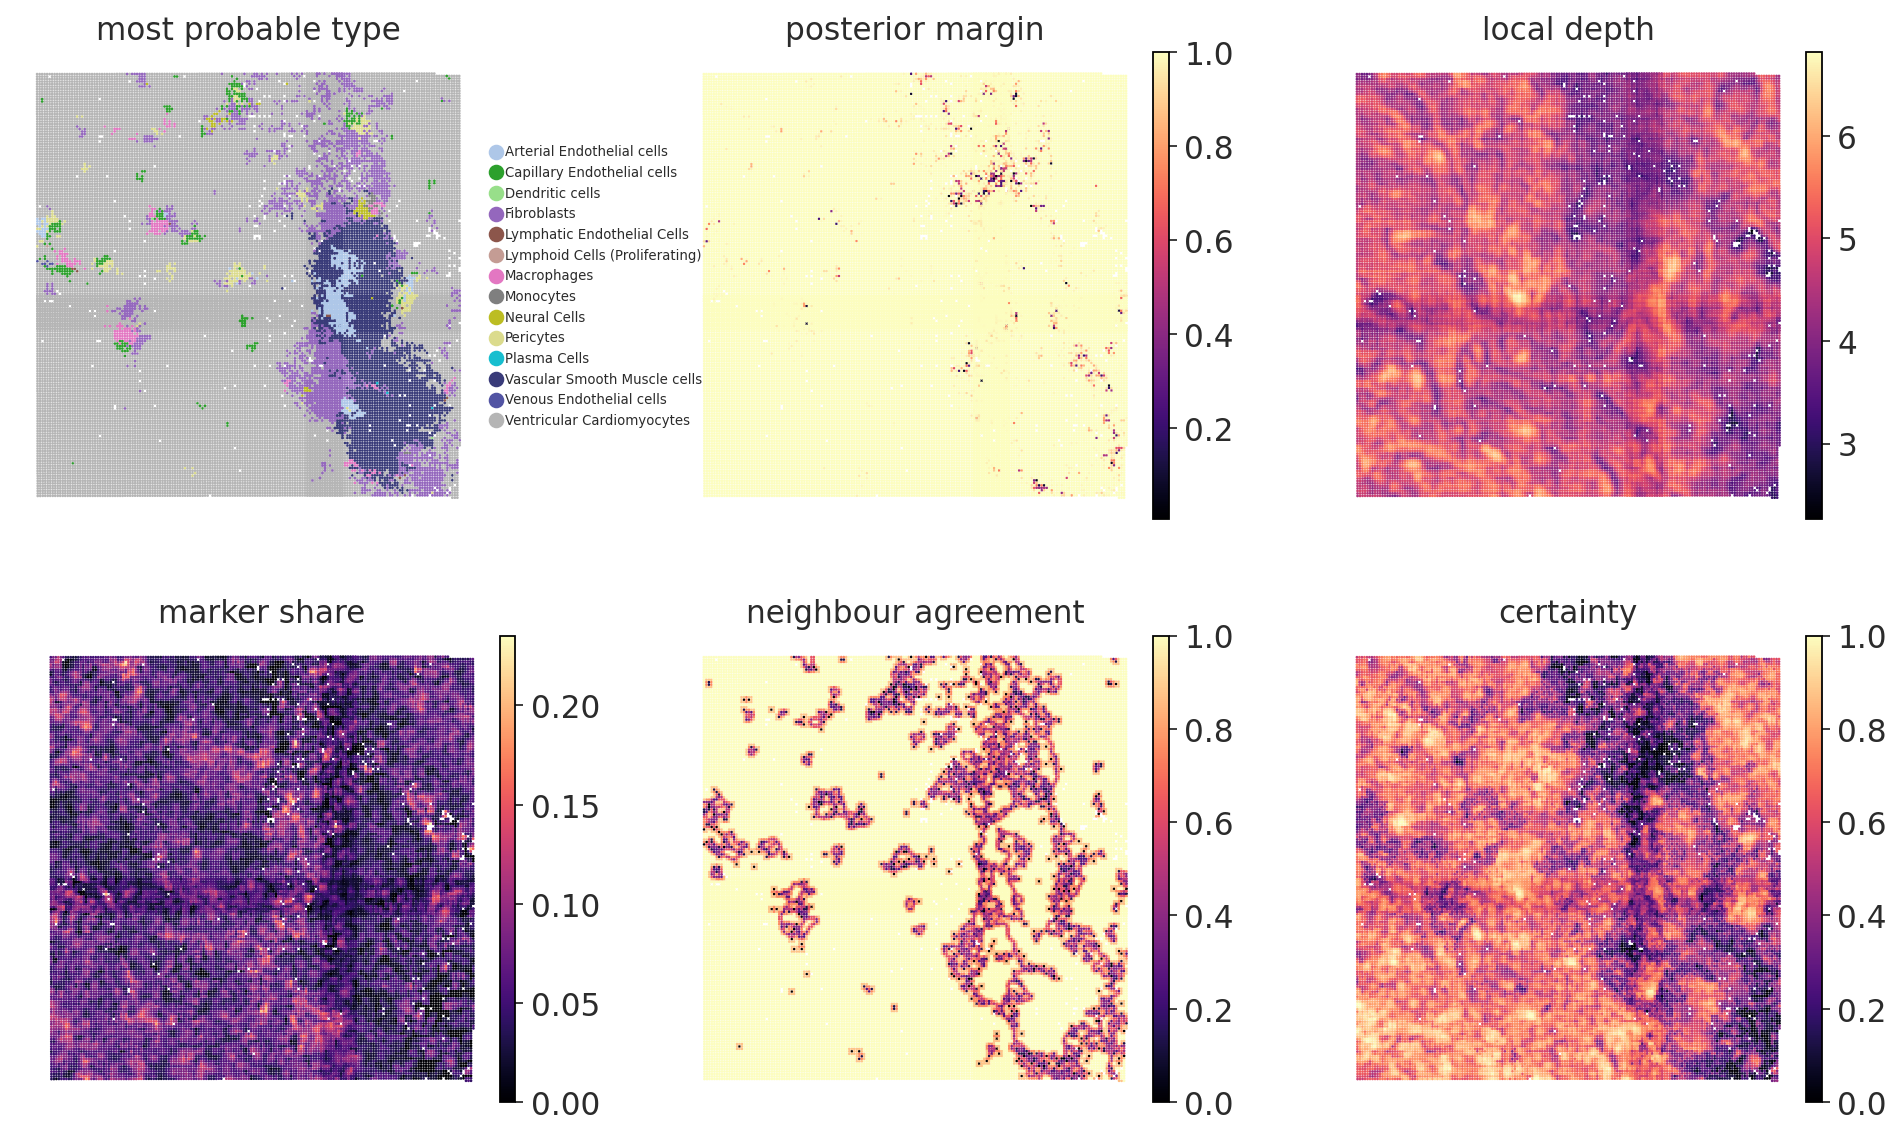

In [12]:
vessel_field = notebook_cfg["vessel_field"]
vessel_centre = np.array(vessel_field["centre_um"])
in_field = hhca.tl.in_window(decode["X"], decode["Y"], vessel_centre, vessel_field["side_um"] / 2)
field_obs = pd.concat([decode.loc[in_field, ["K1", "certainty"]], components[in_field]], axis=1)
field = ad.AnnData(
    obs=field_obs.reset_index(drop=True),
    obsm={"spatial": decode.loc[in_field, ["X", "Y"]].to_numpy()},
)
field.obs["label"] = pd.Categorical.from_codes(field.obs["K1"], categories=factor_order).remove_unused_categories()
style.set_colors(field, "label", style.SPATIAL)
axes = sc.pl.embedding(
    field,
    basis="spatial",
    color=["label", "margin", "depth_raw", "marker_raw", "spatial_raw", "certainty"],
    title=["most probable type", "posterior margin", "local depth", "marker share", "neighbour agreement", "certainty"],
    cmap=style.SEQUENTIAL,
    size=6,
    ncols=3,
    legend_fontsize=6,
    show=False,
)
for ax in axes:
    ax.invert_yaxis()
    ax.set_aspect("equal")
plt.show()

On this section the score has a median of 0.66 (quartiles 0.55 and 0.75). In the field, the posterior margin is
1 almost everywhere, whereas depth and marker share drop along the vessel and neighbour agreement drops at every
border between two cell types; the score follows these three.

### Where to put the threshold?

A score needs a threshold, and a threshold needs something to be measured against. The pipeline decodes every
Berlin section two more times with different FICTURE settings, and the stored tables record whether the call of a
pixel is the same in all decodes (`cross_stable_bin`). We call a pixel *supported* when it has marker transcripts
of its type in the neighbourhood and a stable call. `hhca.tl.precision_coverage` then asks, for 101 thresholds:
what share of the pixels do we keep (coverage), and what share of the kept pixels is supported (precision)?

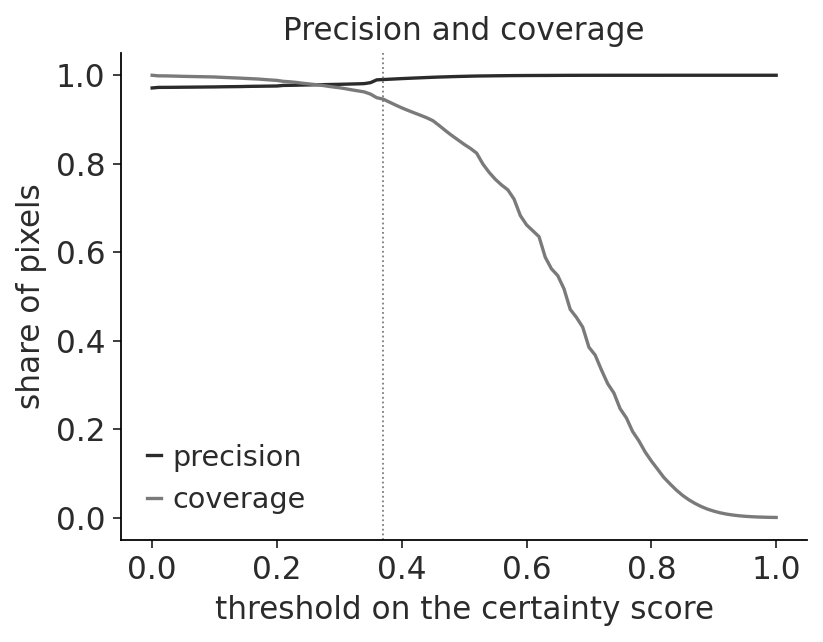

1,439,505 sampled pixels, precision without a threshold 0.971
threshold 0.37: precision 0.990, coverage 0.946


In [13]:
curve = hhca.tl.precision_coverage(sample, quantiles, score_weights)
threshold = hhca.tl.select_threshold(
    curve.dropna(),
    target_precision=certainty_cfg["target_precision"],
    min_coverage=certainty_cfg["min_coverage"],
)
ax = curve.plot(x="threshold", y=["precision", "coverage"], color=[style.INK, style.MUTED], figsize=(5.5, 4))
ax.axvline(threshold, color=style.MUTED, lw=0.8, ls=":")
ax.set(xlabel="threshold on the certainty score", ylabel="share of pixels", title="Precision and coverage")
plt.show()
n_sampled = curve.attrs["n_rows"]
precision_without_threshold = curve["precision"].iloc[0]
chosen = curve.set_index("threshold").loc[threshold]
print(f"{n_sampled:,} sampled pixels, precision without a threshold {precision_without_threshold:.3f}")
print(f"threshold {threshold:.2f}: precision {chosen['precision']:.3f}, coverage {chosen['coverage']:.3f}")

Without a threshold, 97.1% of the 1,439,505 sampled pixels are supported. The lowest threshold that reaches a
precision of 99% is 0.37; it keeps 94.6% of the pixels.

## One threshold does not fit all cell types

A cardiomyocyte is large and full of transcripts; an endothelial cell is a thin sheet, and a lymphocyte is small.
Their pixels have less depth and fewer marker transcripts for a reason that has nothing to do with the quality of
the call. To see how the score behaves per type, `hhca.tl.pool_type_samples` draws up to 250,000 pixels of every
type from each of the eight sections and scores them. The sections are passed in alphabetical order, the order in
which the pipeline draws from them.

In [14]:
global_tau = tau_cfg["global_tau"]
features_alphabetical = {name: features[name] for name in sorted(features)}
pooled, n_pixels = hhca.tl.pool_type_samples(
    features_alphabetical,
    len(factor_order),
    quantiles,
    score_weights,
    cap=tau_cfg["sample_cap"],
    seed=tau_cfg["sampling_seed"],
)
pooled_scores = {}
for code, values in pooled.items():
    if values is not None:
        pooled_scores[code] = values["cert_global"]
scores_by_type = {factor_order[code]: pd.Series(values) for code, values in pooled_scores.items()}
scores = pd.concat(scores_by_type, names=["cell type"]).rename("certainty")
scores = scores.reset_index(level=0)
kept_global = (scores["certainty"] >= global_tau).groupby(scores["cell type"]).mean()
n_sampled_types = scores["cell type"].nunique()
print(f"{len(scores):,} sampled pixels of {n_sampled_types} types")
lowest_kept = 100 * kept_global.sort_values()
lowest_kept.round(1).to_frame(f"% of pixels with a score of at least {global_tau}").head(8)

4,767,044 sampled pixels of 23 types


,% of pixels with a score of at least 0.37
cell type,
Epicardium,5.3
B cells,7.0
ILC,7.1
Lymphatic Endothelial Cells,12.3
Mast cells,14.1
Lymphoid Cells (Proliferating),23.9
Adipocytes,26.4
T cells,29.1


`hhca.tl.fit_type_thresholds` therefore repeats the scaling within each type: depth and marker share are scaled
between the 5th and 95th percentile of the type itself. The share of a type's pixels that reach 0.37 on this
density-corrected score is `cov_corrected`. `hhca.tl.type_thresholds` then returns, for every type, the threshold
on the original score that keeps exactly this share. The pipeline makes the same two calls in
`scripts/substrate/fit_type_thresholds.py` and `assign_with_thresholds.py`.

In [15]:
fit = hhca.tl.fit_type_thresholds(
    pooled,
    n_pixels,
    model,
    markers,
    quantiles,
    score_weights,
    global_tau=global_tau,
    rare_types=tau_cfg["rare_types"],
)
tau = hhca.tl.type_thresholds(fit["thresholds"], pooled_scores, factor_order, global_tau=global_tau)
coverage_columns = ["n_argmax_bins", "cov_global", "cov_corrected"]
thresholds = fit["thresholds"].set_index("cell_type")[coverage_columns].copy()
thresholds["tau"] = tau
thresholds.sort_values("tau").round(4)

,n_argmax_bins,cov_global,cov_corrected,tau
cell_type,,,,
NK cells,944,0.3114,0.6727,0.2034
Lymphatic Endothelial Cells,34583,0.1227,0.4623,0.2065
Mast cells,396,0.1414,0.4091,0.2066
Adipocytes,23503,0.2640,0.5584,0.2233
Neural Cells,47378,0.2949,0.6363,0.2308
Epicardium,1368,0.0534,0.2025,0.2463
Lymphoid Cells (Proliferating),3996,0.2390,0.5708,0.2472
T cells,525,0.2914,0.5486,0.2523
ILC,2328,0.0709,0.2410,0.2526


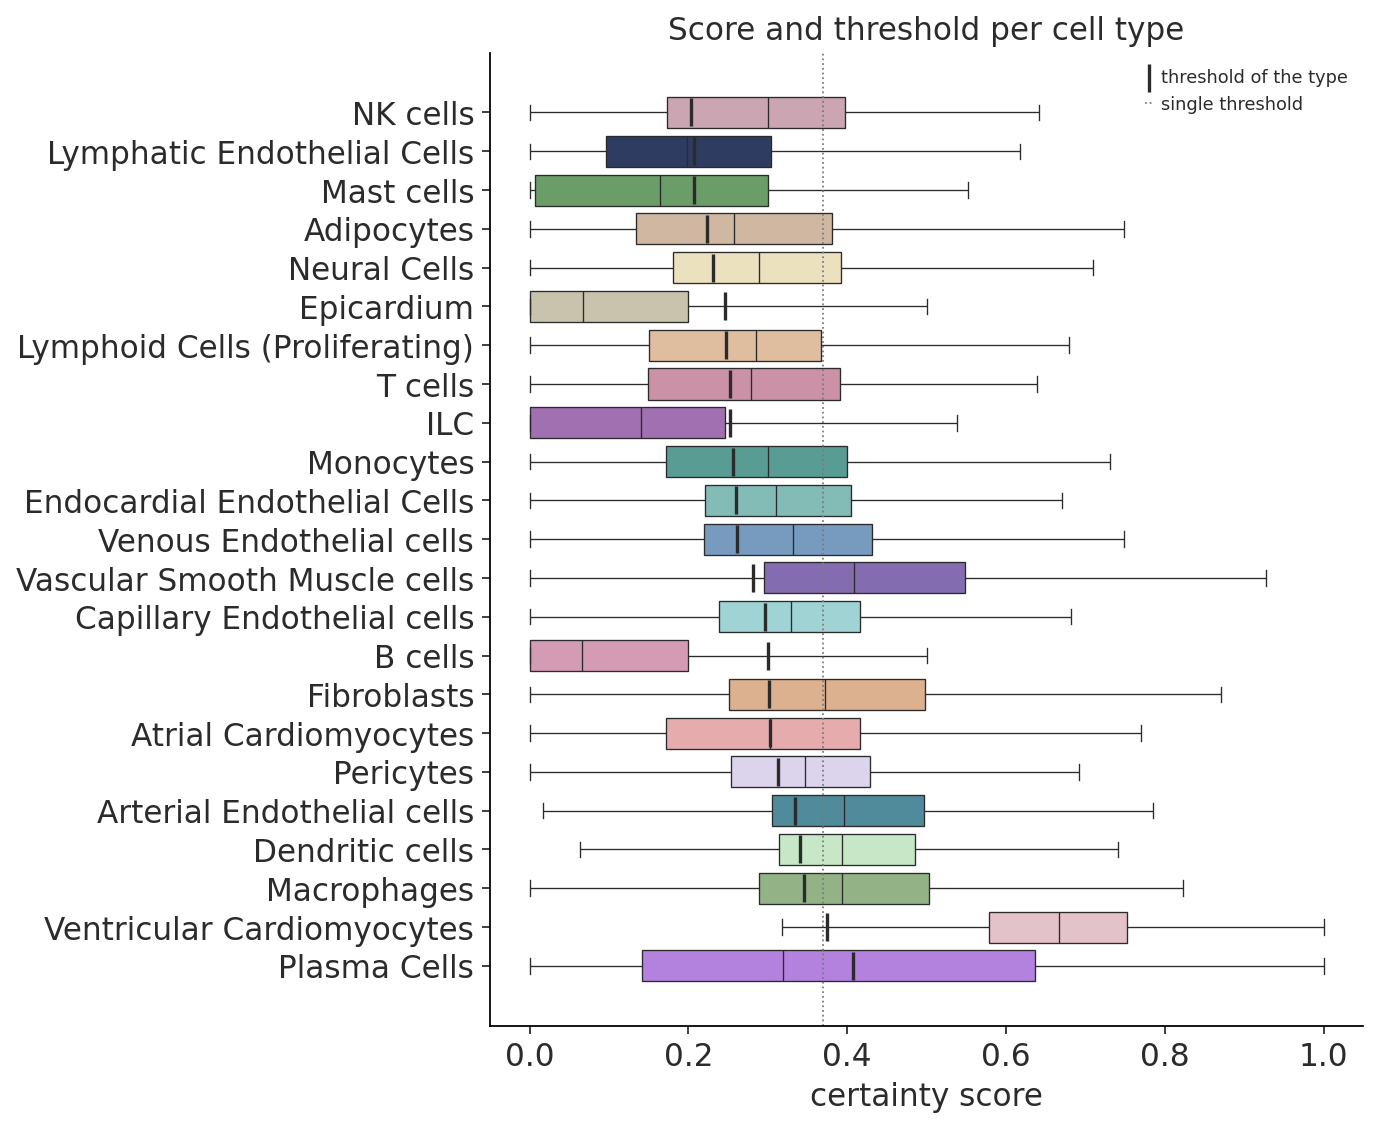

In [16]:
order = tau.sort_values().index
fig, ax = plt.subplots(figsize=(7, 8))
sns.boxplot(
    scores,
    x="certainty",
    y="cell type",
    hue="cell type",
    order=order,
    palette=style.CT,
    fliersize=0,
    linewidth=0.6,
    ax=ax,
)
ax.scatter(tau[order], range(len(order)), marker="|", s=160, color=style.INK, zorder=3, label="threshold of the type")
ax.axvline(global_tau, color=style.MUTED, lw=0.8, ls=":", label="single threshold")
ax.set(xlabel="certainty score", ylabel="", title="Score and threshold per cell type")
ax.legend(loc="upper right", fontsize=8)
plt.show()

At 0.37 the single threshold keeps 96.5% of the ventricular-cardiomyocyte pixels but only 5.3% of the
epicardial, 7.0% of the B-cell and 12.3% of the lymphatic-endothelial pixels. The thresholds per type range from
0.20 (NK cells) to 0.41 (plasma cells); that of ventricular cardiomyocytes stays at 0.37.

### Assigning the pixels

With the thresholds we can assign the pixels. `hhca.tl.assignment_schemes` compares five ways of doing so on our
section: the most probable type without a threshold, with the single threshold, with the threshold of its type,
and two layered versions in which a pixel can also take its second to fifth type if that one passes its threshold
and is rarer (or more abundant) than the first.

In [17]:
schemes = hhca.tl.assignment_schemes(
    decode, decode["certainty"], tau, n_pixels, global_tau=global_tau, p_floor=tau_cfg["p_floor"]
)
ventricular_code = factor_order.index("Ventricular Cardiomyocytes")
rows = []
for assigned in schemes.values():
    assigned_types = assigned[assigned >= 0]
    rows.append(
        {
            "assigned (%)": 100 * (assigned >= 0).mean(),
            "not ventricular CM (% of assigned)": 100 * (assigned_types != ventricular_code).mean(),
            "types with pixels": len(np.unique(assigned_types)),
        }
    )
comparison = pd.DataFrame(rows, index=list(schemes))
comparison.round(2)

,assigned (%),not ventricular CM (% of assigned),types with pixels
decode_argmax,100.00,5.40,23
global_037,92.99,2.84,21
pertype,93.69,3.84,22
pertype_rare_first,93.97,4.79,23
pertype_abund_first,93.97,3.81,23


Without a threshold, 5.40% of the pixels of this section are not ventricular cardiomyocytes. The single threshold
assigns 92.99% of the pixels, leaves 2.84% other types among them and loses two types altogether. The thresholds
per type keep 3.84%, and the layered scheme with rare types first 4.79% in 93.97% of the pixels, with all 23
types present.

## The 2 µm and 8 µm AnnData

Now we bring calls and counts together. A 2 µm bin of Space Ranger holds several decode pixels.
`hhca.tl.bins_2um` represents every bin by its pixel with the highest posterior, finds the bin on the Space Ranger
grid and returns an `AnnData` with the raw counts in `X`. The label of a bin, `obs["L3_label"]`, is the most
probable type of that pixel; its certainty score is kept next to it as `obs["gcert"]`, so that every later
analysis can choose its own threshold.

In [18]:
region = cfg["slides"][section]["region"]
bin_certainty = decode["certainty"].round(4)
adata = hhca.tl.bins_2um(decode, bins, factor_order, section, region, certainty=bin_certainty)
adata

AnnData object with n_obs × n_vars = 7617308 × 18085
    obs: 'L3_label', 'gcert', 'posterior_max', 'x_um', 'y_um', 'slide'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'build'

In [19]:
pd.Series(adata.uns["build"])[
    ["decode_rows", "unique_2um_bins", "matched_bins", "coverage_pct", "join_residual_um_median"]
]

decode_rows                  9030539
unique_2um_bins              7620385
matched_bins                 7617308
coverage_pct               99.959621
join_residual_um_median     0.078724
dtype: object

For an overview of a section, and for analyses that need more transcripts per unit, the pipeline also writes 8 µm
bins. `hhca.tl.bins_8um` gives every 8 µm bin of Space Ranger the most frequent label of its 2 µm bins and stores
the share of every label in `obsm["L3_composition"]`. For every section, the two objects are written by
`scripts/substrate/build_2um_h5ad.py` and `build_8um_h5ad.py`.

In [20]:
positions = hhca.tl.read_bin_positions(section_path(cfg, "square_002um", section))
space_ranger_8um = hhca.tl.read_bins(section_path(cfg, "square_008um", section))
adata_8um = hhca.tl.bins_8um(decode, positions, space_ranger_8um, factor_order, section, certainty=bin_certainty)
adata_8um

AnnData object with n_obs × n_vars = 512776 × 18085
    obs: 'L3_label', 'L3_top1_frac', 'gcert_mean', 'n_2um_bins', 'x_um', 'y_um', 'slide'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'L3_composition_order', 'slide', 'build'
    obsm: 'L3_composition', 'spatial'

We plot the Level-3 labels of the 8 µm bins in tissue coordinates, in the colours of the spatial panels
(`style.SPATIAL`).

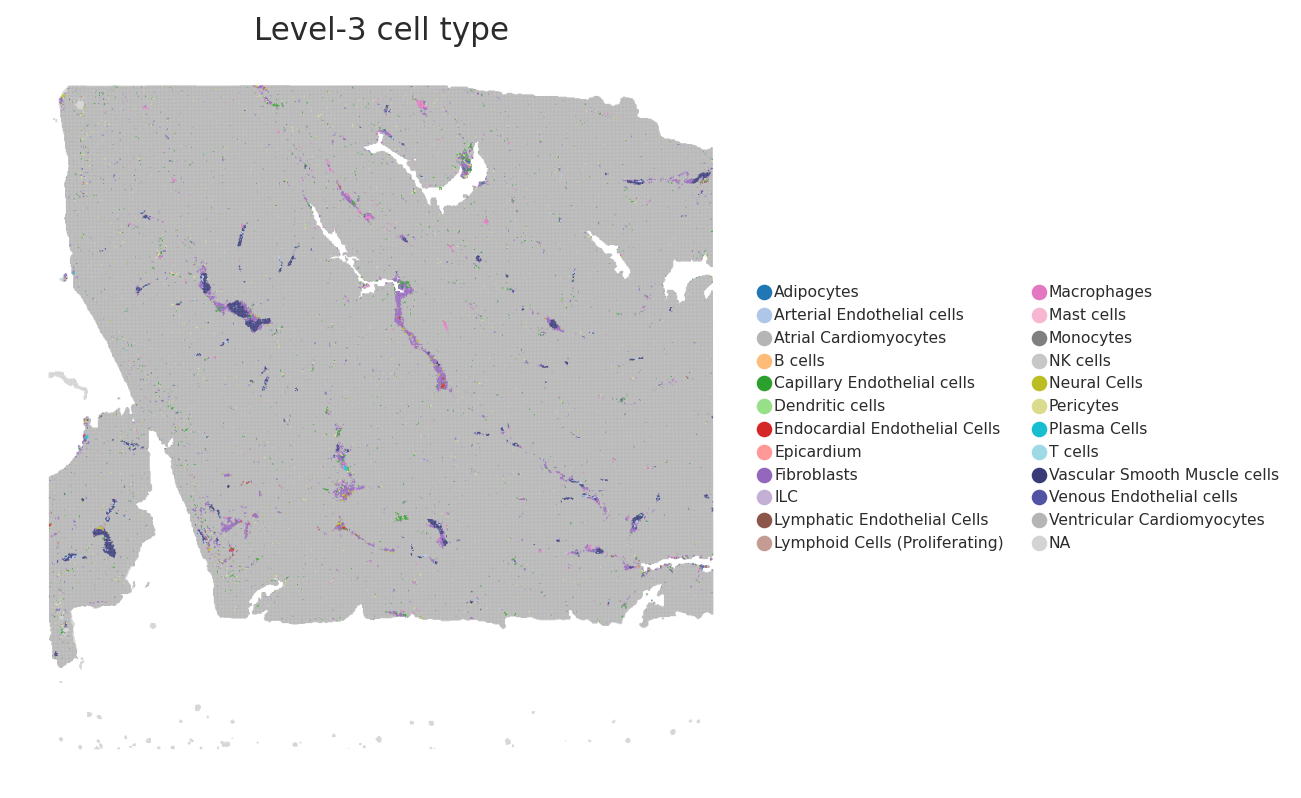

In [21]:
style.set_colors(adata_8um, "L3_label", style.SPATIAL)
with plt.rc_context({"figure.figsize": (6, 6)}):
    ax = sc.pl.embedding(
        adata_8um, basis="spatial", color="L3_label", size=1, legend_fontsize=7, title="Level-3 cell type", show=False
    )
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

Of the 7,620,385 2 µm bins with a decode pixel, 7,617,308 (99.96%) are found on the Space Ranger grid, with a
median distance of 0.08 µm between the two positions; the section has 512,776 bins of 8 µm.

## Transcripts in empty space

On the map above, the section looks densely filled. The H&E image of the same section tells a different story:
vessels have a lumen, and the tissue has gaps and tears. Yet Visium HD captures transcripts there too, because RNA
diffuses out of the cells before it is captured, and the decode faithfully calls them cardiomyocytes or smooth
muscle. These bins are not cells, and we do not want them in an analysis of vessel walls or of cell
neighbourhoods.

To find them we need to know where the tissue ends, at the resolution of a bin. The microscope image of the
section is registered to the image that the CytAssist instrument took during the Visium run (SIFT features, a
RANSAC affine fit and an ECC refinement). This is part of the flagging job of the pipeline, which stores the map
from µm to image pixels:

```bash
sbatch workflow/hpc/substrate_cmflag_flags.sbatch VS_CA_H0054LV_henricke_endo
```

We load the registration, the microscope image and the CytAssist image.

In [22]:
section_inputs = cmflag["slides"][section]
roots = resolve_roots(cmflag)
inputs = {key: fill(value, roots, slide=section, base=section_inputs["base"]) for key, value in section_inputs.items()}
registration = np.load(section_path(cfg, "registration", section))
image = tifffile.memmap(inputs["tif"], mode="r")
cytassist_path = f"{inputs['spaceranger']}/binned_outputs/square_008um/spatial/tissue_hires_image.png"
cytassist = np.asarray(Image.open(cytassist_path).convert("RGB"))
registered_correlation = float(registration["ncc"])
print(f"microscope image {image.shape[1]:,} x {image.shape[0]:,} pixels")
print(f"CytAssist image {cytassist.shape[1]:,} x {cytassist.shape[0]:,} pixels")
print(f"correlation of the registered images: {registered_correlation:.3f}")

microscope image 30,111 x 17,521 pixels
CytAssist image 6,000 x 3,491 pixels
correlation of the registered images: 0.993


`hhca.tl.sample_he` reads the H&E at the position of every decode pixel. An affine map cannot follow local
stretching of the section, so the function first measures the remaining shift between the two images on a 300 µm
lattice and corrects every pixel by the shift at its position. It returns the grey value and, after colour
deconvolution, the optical density of eosin (cytoplasm) and haematoxylin (nuclei).

In [23]:
x, y = decode["X"].to_numpy(), decode["Y"].to_numpy()
um_to_px = (registration["M0"], registration["t0"])
cytassist_um_per_px = float(registration["CMPP"])
microscopy = hhca.tl.Microscopy(image, cytassist, um_to_px, cytassist_um_per_px)
he = hhca.tl.sample_he(microscopy, x, y)
offset_field = he.attrs["field"]
print(f"offset measured in {offset_field['nkeep']} of {offset_field['ncells']} lattice tiles")
he.describe().loc[["mean", "25%", "50%", "75%"]].round(3)

offset measured in 349 of 418 lattice tiles


,eosin_od,hema_od,grey_cyt,grey
mean,0.020,0.042,146.454,147.434
25%,0.009,0.031,120.883,119.621
50%,0.024,0.040,133.087,133.511
75%,0.029,0.049,157.614,158.735


A pixel lies on whitespace when the image is bright there (grey above 235) or shows no eosin (optical density
below 0.008). A pixel with a clear haematoxylin signal holds a nucleus, whatever its surroundings look like;
`hhca.tl.nucleus_gate` sets the threshold between the haematoxylin levels of whitespace and of tissue on this
section.

In [24]:
whitespace_cuts = cmflag["whitespace"]
bright = he["grey"] > whitespace_cuts["grey"]
no_eosin = he["covered"] & (he["eosin_od"] < whitespace_cuts["eosin_od"])
he["whitespace"] = bright | no_eosin
he["nucleus"], gate = hhca.tl.nucleus_gate(
    he["hema_od"], he["covered"], he["whitespace"], fraction=cmflag["nucleus_fraction"]
)
print(f"haematoxylin of whitespace {gate['nucleus_hfloor']:.4f}, of tissue {gate['nucleus_htiss']:.4f}")
print(f"threshold for a nucleus {gate['nucleus_thr']:.4f}")
pixel_shares = 100 * he[["covered", "whitespace", "nucleus"]].mean()
pixel_shares.round(1).to_frame("% of decode pixels").T

haematoxylin of whitespace 0.0259, of tissue 0.0419
threshold for a nucleus 0.0315


,covered,whitespace,nucleus
% of decode pixels,100.0,23.8,73.9


The offset between the two images could be measured in 349 of the 418 lattice tiles. 23.8% of the decode pixels
lie on whitespace, and 73.9% show haematoxylin above the nucleus threshold (0.0315, between 0.0259 on whitespace
and 0.0419 on tissue).

### The spillover rule

Which pixels on whitespace are spillover? `hhca.tl.marker_depth` returns two things for every pixel: how deep it
lies in the whitespace (the distance to the nearest tissue, in µm), and how many marker transcripts of
cardiomyocytes, smooth muscle and endothelium its 2 µm bin holds.

In [25]:
on_whitespace = he["whitespace"].to_numpy()
bin_markers = hhca.tl.marker_depth(bins, x, y, on_whitespace, cmflag["markers"])
print(pd.Series(cmflag["markers"]).str.join(", ").to_string())
bin_markers[on_whitespace].describe().loc[["mean", "50%", "max"]].round(3)

cm        TNNT2, MYH6, MYL7, ACTC1, MYH7, TNNI3
vsmc     MYH11, ACTA2, TAGLN, MYL9, CNN1, LMOD1
art     SEMA3G, GJA5, HEY1, EFNB2, PECAM1, CDH5
ven             ACKR1, NR2F2, VWF, PECAM1, CDH5
ecg                           PECAM1, CDH5, VWF
vsg                         MYH11, ACTA2, TAGLN
cmg                          TNNT2, MYL7, ACTC1


,depth_bin,cm_bin,vsmc_bin,art_bin,ven_bin,ecg_bin,vsg_bin,cmg_bin
mean,6.387,0.569,0.045,0.01,0.024,0.023,0.016,0.44
50%,4.000,0.000,0.000,0.00,0.000,0.000,0.000,0.00
max,204.216,34.000,7.000,4.00,5.000,5.000,4.000,20.00


If the marker transcripts in whitespace diffused there from the tissue, their density should fall with the
distance from the tissue edge. We look at this for the cardiomyocyte markers, next to the exponential decay that
was fitted once on section BO_HDZ and is used for all sections.

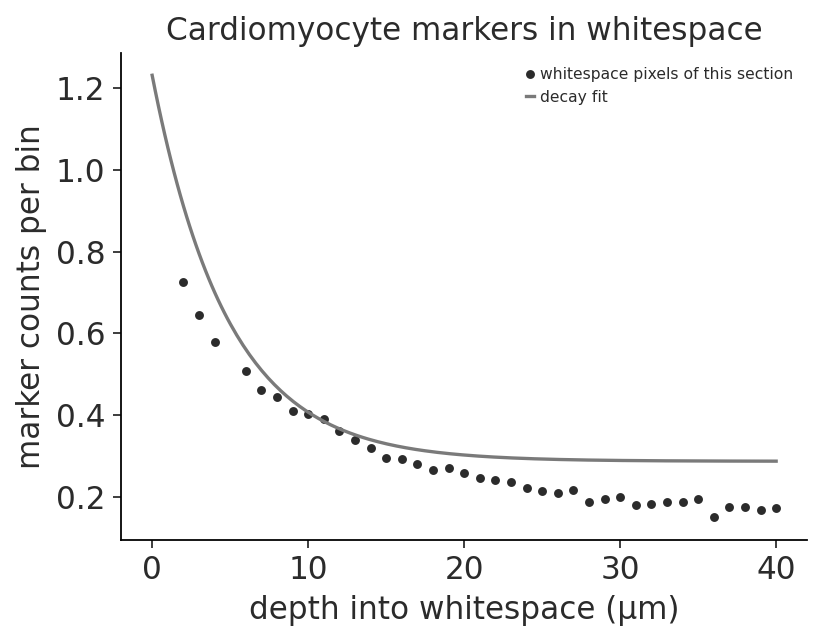

decay length: cardiomyocyte markers 4.8 µm, smooth muscle 20.1 µm


In [26]:
max_depth_um = 40  # deeper pixels are shown together with those at this depth
fits = {}
for name in ("cm", "vsmc"):
    fit_path = fill(cmflag["shared"][f"{name}_fit"], roots)
    fits[name] = pd.read_json(fit_path, typ="series").to_dict()
in_gap = bin_markers[on_whitespace & (bin_markers["depth_bin"] > 0)]
depth = in_gap["depth_bin"].round().clip(upper=max_depth_um)
mean_by_depth = in_gap.groupby(depth)["cm_bin"].mean()
cm_fit = fits["cm"]
depth_grid = np.linspace(0, max_depth_um, 200)
cm_decay = cm_fit["A"] * np.exp(-depth_grid / cm_fit["lam"]) + cm_fit["b"]
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(mean_by_depth.index, mean_by_depth, "o", ms=3, color=style.INK, label="whitespace pixels of this section")
ax.plot(depth_grid, cm_decay, color=style.MUTED, label="decay fit")
ax.set(
    xlabel="depth into whitespace (µm)",
    ylabel="marker counts per bin",
    title="Cardiomyocyte markers in whitespace",
)
ax.legend(fontsize=7)
plt.show()
cm_decay_um = cm_fit["lam"]
vsmc_decay_um = fits["vsmc"]["lam"]
print(f"decay length: cardiomyocyte markers {cm_decay_um:.1f} µm, smooth muscle {vsmc_decay_um:.1f} µm")

The cardiomyocyte marker counts fall steeply over the first 10 µm of whitespace and level off further out, as
the fitted decay does (decay length 4.8 µm; 20.1 µm for the smooth-muscle markers).

The flags apply to pixels of four cell types. For this step a pixel is assigned with the layered scheme from
above, rare types first, using the thresholds per type with four decimals as the pipeline stores them; the
thresholds of all types other than cardiomyocytes are multiplied by 0.3 (`hhca.tl.flag_thresholds`), so that a
weak vessel or immune call is not turned into a cardiomyocyte call.

In [27]:
assignment_cfg = cmflag["assignment"]
tau_rounded = {name: round(float(value), 4) for name, value in tau.items()}
flag_tau = hhca.tl.flag_thresholds(
    tau_rounded, factor_order, assignment_cfg["unscaled"], scale=assignment_cfg["rare_tau_scale"]
)
decode["assigned"] = hhca.tl.assign_labels(decode, decode["certainty"], flag_tau, p_floor=assignment_cfg["p_floor"])
share_unassigned = (decode["assigned"] < 0).mean()
print(f"{share_unassigned:.2%} of the pixels are not assigned")
pd.DataFrame(cmflag["flags"]).T

3.99% of the pixels are not assigned


,types,markers,guards,decay
flag_cm_spillover,"[Ventricular Cardiomyocytes, Atrial Cardiomyoc...",cm,[ecg],cm
flag_vsmc_spillover,[Vascular Smooth Muscle cells],vsmc,[ecg],vsmc
flag_spill_artEC,[Arterial Endothelial cells],art,"[cmg, vsg]",vsmc
flag_spill_venEC,[Venous Endothelial cells],ven,"[cmg, vsg]",vsmc


`hhca.tl.spillover_flags` applies the rule in the table. A pixel gets the flag of its type when it lies on
whitespace, the decay explains at least 80% of the marker counts in its bin, the bin holds no marker of a
competing type (the guards), and the pixel has no nucleus. The endothelial flags use the decay of the
smooth-muscle markers.

In [28]:
flags = hhca.tl.spillover_flags(
    decode["assigned"],
    factor_order,
    bin_markers,
    he["whitespace"],
    he["nucleus"],
    cmflag["flags"],
    fits,
    min_share=cmflag["min_spillover_share"],
)
flag_counts = flags.sum().rename(style.SPILLOVER_LABELS).to_frame("flagged pixels")
flag_counts["% of pixels"] = (100 * flag_counts["flagged pixels"] / len(flags)).round(2)
flag_counts

,flagged pixels,% of pixels
cardiomyocyte,682370,7.56
VSMC,14076,0.16
arterial EC,3292,0.04
venous EC,2613,0.03


3.99% of the pixels are not assigned. 682,370 pixels (7.56%) carry the cardiomyocyte flag, 14,076 the
smooth-muscle flag, 3,292 the arterial and 2,613 the venous endothelial flag.

## The clean-up

The clean-up removes the bins that carry one of the four spillover flags, and nothing else. The flags are per
decode pixel; `hhca.tl.bin_flags` brings them to the 2 µm bins, where a bin carries a flag if any of its pixels
does.

In [29]:
pixel_flags = pd.concat([decode[["X", "Y"]], flags], axis=1)
per_bin = hhca.tl.bin_flags(pixel_flags, adata)
flagged = per_bin.any(axis=1).to_numpy()
flag_of_bin = np.where(flagged, per_bin.idxmax(axis=1), "none")
adata.obs["flag"] = pd.Categorical(flag_of_bin, categories=["none", *SPILLOVER_FLAGS])
clean = adata[~flagged].copy()
n_flagged = flagged.sum()
share_flagged = flagged.mean()
print(f"{n_flagged:,} of {adata.n_obs:,} bins are flagged ({share_flagged:.1%}); {clean.n_obs:,} bins remain")

601,957 of 7,617,308 bins are flagged (7.9%); 7,015,351 bins remain


At 8 µm a bin is not removed as a whole. `hhca.tl.clean_bins_8um` subtracts the counts of the flagged 2 µm bins
from their 8 µm bin and takes label and composition from the remaining 2 µm bins; only 8 µm bins that consist of
flagged bins alone are dropped. For every section, `scripts/substrate/cmflag/build_cmflag_clean_h5ads.py` writes
the clean 2 µm and 8 µm objects.

In [30]:
clean_8um, clean_stats = hhca.tl.clean_bins_8um(adata, adata_8um, flagged)
pd.Series(clean_stats).to_frame("8 µm bins").T

,n_8um,n_8um_dropped_all_flagged,n_8um_clean,pct_8um_counts_removed,frac_2um_assigned_to_8um,frac_full_blocks_exact_sum,n_8um_negative_entries_clipped,pct_8um_counts_clipped
8 µm bins,512776.0,812.0,511964.0,5.456,1.0,0.99929,46525.0,0.0329


### What is removed?

We first look at the flagged bins on the H&E. `hhca.tl.he_window` cuts a field out of the registered image
together with its bins, and `hhca.pl.he_fields` draws the bins on top: the non-cardiomyocyte labels in their
colours, the flagged bins in the colour of their flag. The first field is the vessel from above; the second is
the 150 µm tile of the section with the most flagged bins.

In [31]:
tile_um = notebook_cfg["tile_um"]
flagged_xy = adata.obs.loc[flagged, ["x_um", "y_um"]]
tiles = flagged_xy.floordiv(tile_um).value_counts()
busiest_tile = np.array(tiles.index[0])  # tile numbers along x and y
busiest_centre = (busiest_tile + 0.5) * tile_um
centres = {"vessel": vessel_centre, "tile with the most flagged bins": busiest_centre}
before = []
after = []
removed = []
rows = []
for centre in centres.values():
    field_before = hhca.tl.he_window(adata, image, um_to_px, centre, tile_um)
    field_after = hhca.tl.he_window(clean, image, um_to_px, centre, tile_um)
    in_tile = hhca.tl.in_window(adata.obs["x_um"], adata.obs["y_um"], centre, tile_um / 2)
    field_removed = adata.obs.loc[flagged & in_tile, ["x_um", "y_um", "flag"]]
    before.append(field_before)
    after.append(field_after)
    removed.append(field_removed)
    rows.append(
        {
            "bins": len(field_before["x"]),
            "flagged": len(field_removed),
            "bins after the clean-up": len(field_after["x"]),
        }
    )
pd.DataFrame(rows, index=list(centres))

,bins,flagged,bins after the clean-up
vessel,5571,1062,4509
tile with the most flagged bins,5341,2438,2903


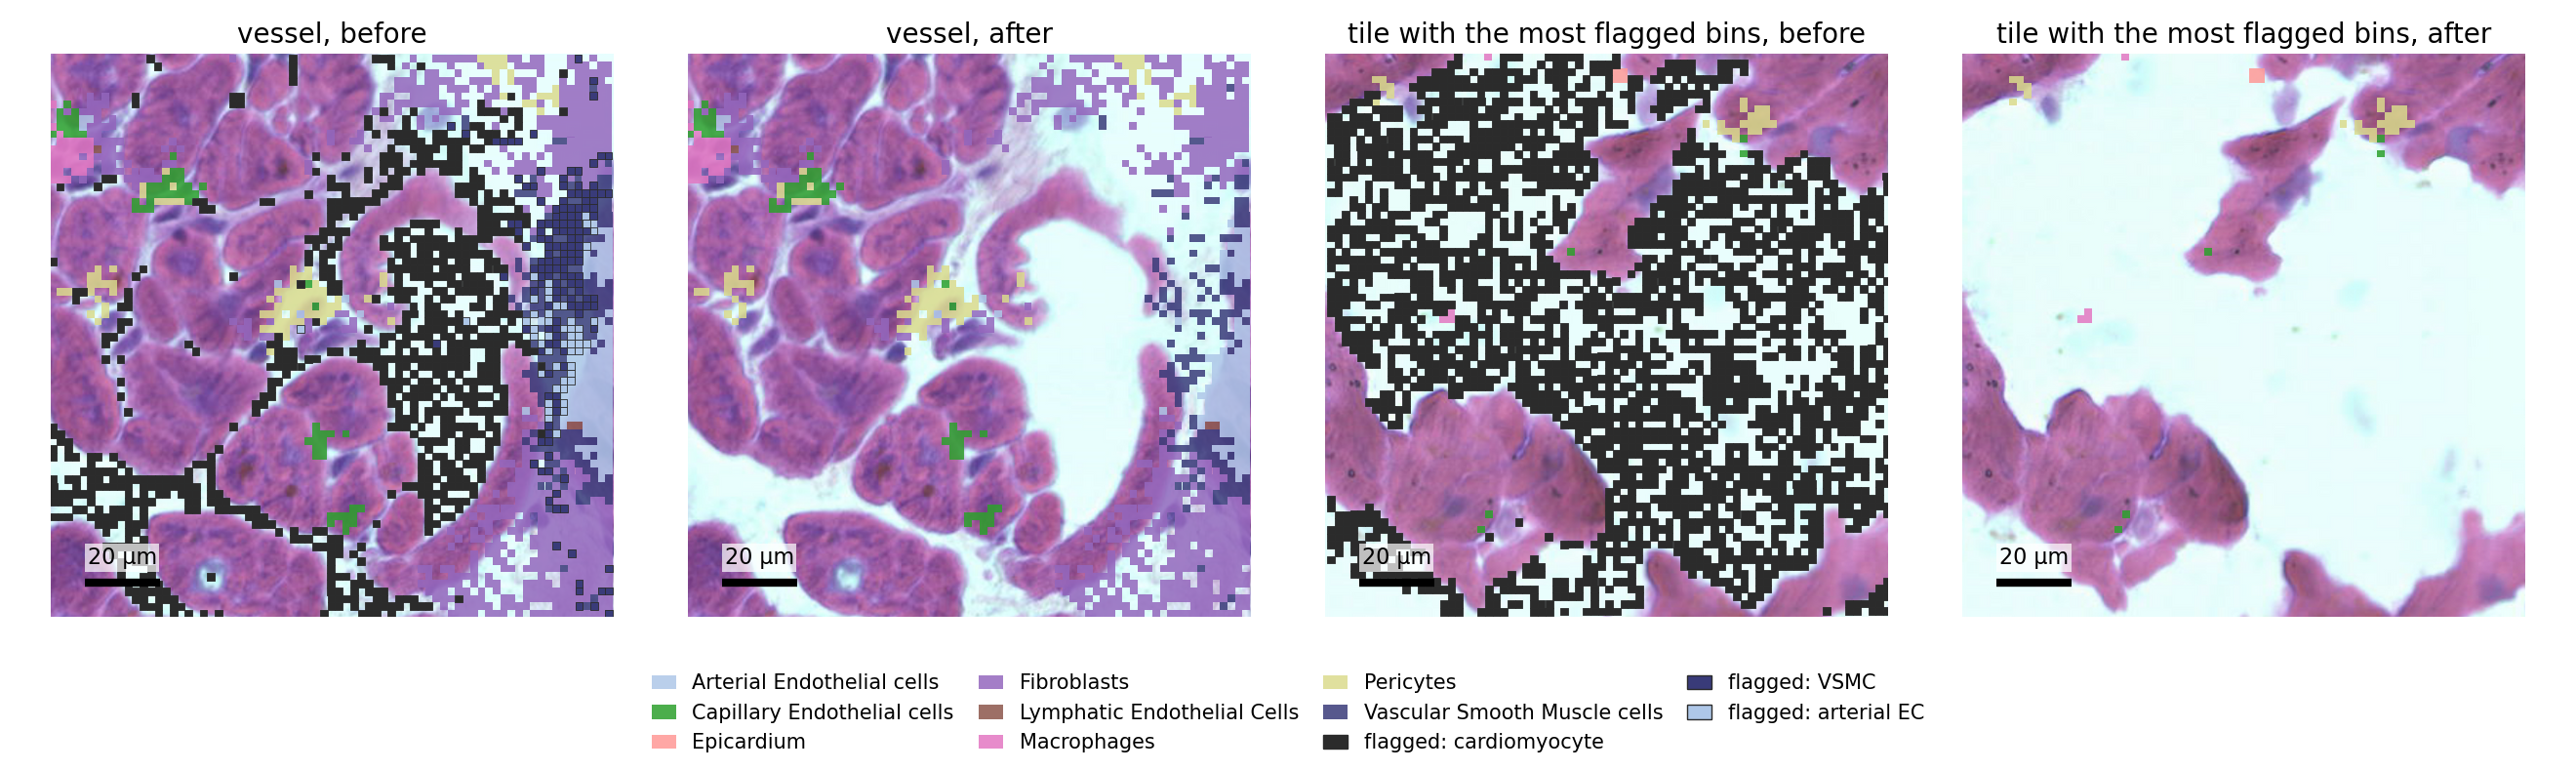

In [32]:
vessel_name, tile_name = centres
titles = [f"{vessel_name}, before", f"{vessel_name}, after", f"{tile_name}, before", f"{tile_name}, after"]
fig = hhca.pl.he_fields(
    [before[0], after[0], before[1], after[1]], titles, flagged=[removed[0], None, removed[1], None]
)

Which labels lose bins? We count the bins of every label by flag.

In [33]:
by_label = pd.crosstab(adata.obs["L3_label"], adata.obs["flag"]).rename(columns=style.SPILLOVER_LABELS)
by_label["% removed"] = 100 * (1 - by_label["none"] / by_label.sum(axis=1))
by_label.sort_values("% removed", ascending=False).round(2).head(8)

flag,none,cardiomyocyte,VSMC,arterial EC,venous EC,% removed
L3_label,,,,,,
Venous Endothelial cells,4514,10,0,0,1829,28.95
Vascular Smooth Muscle cells,40027,25,10218,274,1,20.81
Arterial Endothelial cells,11060,12,19,2456,6,18.39
Ventricular Cardiomyocytes,6621934,583964,1311,127,192,8.12
Atrial Cardiomyocytes,5359,352,0,0,1,6.18
Fibroblasts,140427,173,504,15,38,0.52
Pericytes,60094,51,36,35,32,0.26
Capillary Endothelial cells,83628,80,65,26,29,0.24


Finally the expression. If the flagged bins are spillover, they should hold fewer transcripts than the bins we
keep, and few transcripts of the marker genes of their type. We compare the flagged and the kept bins of the four
flagged types.

In [34]:
adata.obs["total_counts"] = np.asarray(adata.X.sum(axis=1)).ravel()
flag_types = {style.SPILLOVER_LABELS[flag]: rule for flag, rule in cmflag["flags"].items()}
rows = {}
for name, rule in flag_types.items():
    of_type = adata.obs["L3_label"].isin(rule["types"]).to_numpy()
    listed_genes = pd.Index(cmflag["markers"][rule["markers"]])
    genes = listed_genes[listed_genes.isin(adata.var_names)]
    masks = {"kept": of_type & ~flagged, "removed": of_type & flagged}
    for state, mask in masks.items():
        subset = adata[mask]
        marker_total = subset[:, genes].X.sum()
        rows[name, state] = {
            "bins": subset.n_obs,
            "counts per bin": subset.obs["total_counts"].mean(),
            "marker counts per bin": marker_total / subset.n_obs,
            "markers (% of counts)": 100 * marker_total / subset.obs["total_counts"].sum(),
        }
expression = pd.DataFrame(rows).T
expression.round(3)

bins  counts per bin  marker counts per bin  \
cardiomyocyte kept     6627293.0          18.243                  0.847   
              removed   585947.0          13.053                  0.222   
VSMC          kept       40027.0          18.128                  0.617   
              removed    10518.0          13.540                  0.039   
arterial EC   kept       11060.0          25.586                  0.190   
              removed     2493.0          18.915                  0.014   
venous EC     kept        4514.0          22.112                  0.317   
              removed     1839.0          14.325                  0.023   

                       markers (% of counts)  
cardiomyocyte kept                     4.641  
              removed                  1.702  
VSMC          kept                     3.403  
              removed                  0.284  
arterial EC   kept                     0.741  
              removed                  0.072  
venous EC     kept                     1.434  
              removed                  0.159

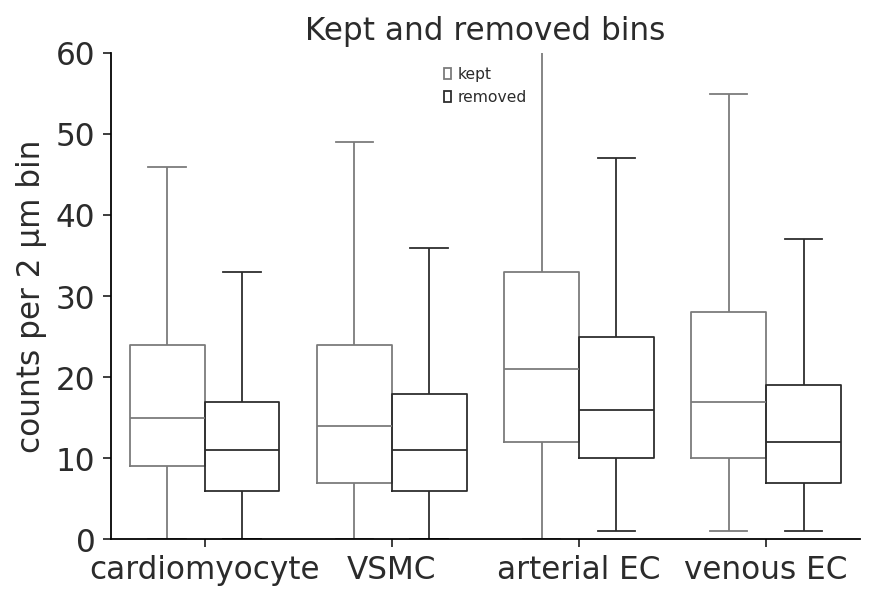

In [35]:
flag_of_type = {}
for name, rule in flag_types.items():
    for cell_type in rule["types"]:
        flag_of_type[cell_type] = name
shown = adata.obs[adata.obs["L3_label"].isin(list(flag_of_type))].copy()
shown["type"] = shown["L3_label"].astype(str).map(flag_of_type)
shown["state"] = np.where(shown["flag"] == "none", "kept", "removed")
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(
    shown,
    x="type",
    y="total_counts",
    hue="state",
    order=list(flag_types),
    hue_order=["kept", "removed"],
    palette=style.KEPT_REMOVED,
    fill=False,
    fliersize=0,
    linewidth=0.8,
    ax=ax,
)
ax.set(xlabel="", ylabel="counts per 2 µm bin", ylim=(0, 60), title="Kept and removed bins")
ax.legend(title="", fontsize=7)
plt.show()

On this section 601,957 of the 7,617,308 bins (7.9%) are removed; 812 of the 512,776 bins of 8 µm are dropped,
and the remaining ones lose 5.46% of their counts. The clean-up takes 28.95% of the venous endothelial, 20.81% of
the smooth-muscle and 18.39% of the arterial endothelial bins, 8.12% of the ventricular and 6.18% of the atrial
cardiomyocyte bins, and at most 0.52% of any other label. Removed bins hold fewer transcripts than kept bins of
the same type (13.1 against 18.2 counts per bin for cardiomyocytes) and far fewer marker transcripts (0.22
against 0.85; 0.04 against 0.62 for smooth muscle).

## All 11 sections

The pipeline runs the steps above on every section: `substrate_certainty.sbatch` (score and thresholds),
`substrate_h5ad.sbatch` (2 µm and 8 µm `AnnData`), `substrate_cmflag_flags.sbatch` (registration and flags) and
`substrate_cmflag_clean.sbatch` (the clean objects). For the three AH sections, which have no certainty score, a
bin is assigned its most probable type; their H&E comes from a different microscope and is read by
`scripts/substrate/cmflag/cmflag_ah.py`.

We open the 2 µm objects of all sections before and after the clean-up without loading the counts and count the
bins per label.

In [36]:
cardiomyocytes = ["Ventricular Cardiomyocytes", "Atrial Cardiomyocytes"]
counts_before = {}
counts_after = {}
for name in all_sections:
    bins_before = ad.read_h5ad(section_path(cfg, "h5ad_2um", name), backed="r")
    bins_after = ad.read_h5ad(section_path(cfg, "h5ad_2um_clean", name), backed="r")
    counts_before[name] = bins_before.obs["L3_label"].value_counts()
    counts_after[name] = bins_after.obs["L3_label"].value_counts()
labels_before = pd.DataFrame(counts_before).fillna(0).astype(int)
labels_after = pd.DataFrame(counts_after).fillna(0).astype(int)
per_section_before = labels_before.sum()
per_section_after = labels_after.sum()
overview = pd.DataFrame(
    {
        "2 µm bins": per_section_before,
        "after the clean-up": per_section_after,
        "% removed": 100 * (1 - per_section_after / per_section_before),
        "% cardiomyocytes after": 100 * labels_after.loc[cardiomyocytes].sum() / per_section_after,
    }
)
n_bins_before = per_section_before.sum()
n_bins_after = per_section_after.sum()
print(f"{n_bins_before:,} bins on {len(overview)} sections")
print(f"{n_bins_after:,} bins after the clean-up")
overview.round(2)

72,683,834 bins on 11 sections
66,558,914 bins after the clean-up


,2 µm bins,after the clean-up,% removed,% cardiomyocytes after
VS_BO_HDZ150319_34_myo,4029508,3626127,10.01,91.37
VS_BO_2024BH-008_myo,3746240,3367499,10.11,98.44
VS_CA_H0054LV_henricke_endo,7617308,7015351,7.90,94.47
VS_CA_H0054LV_henricke_epi,8845161,7633492,13.70,97.02
VS_CA_H0054LV_henricke_myo,8325539,7701469,7.50,97.08
VS_CA_H0063LV_henricke_endo,6458997,5739584,11.14,95.42
VS_CA_H0063LV_henricke_epi,8050642,7442651,7.55,97.38
VS_CA_H0063LV_henricke_myo,7506234,6798677,9.43,96.85
VS_AH9_LV_FW_epi,5893567,5476477,7.08,90.72
VS_AH10_LV_mid_endo,6808683,6691420,1.72,92.03


Cardiomyocytes make up most of every section, so we plot the composition of the other labels after the clean-up,
in the colours of the atlas (`style.CT`).

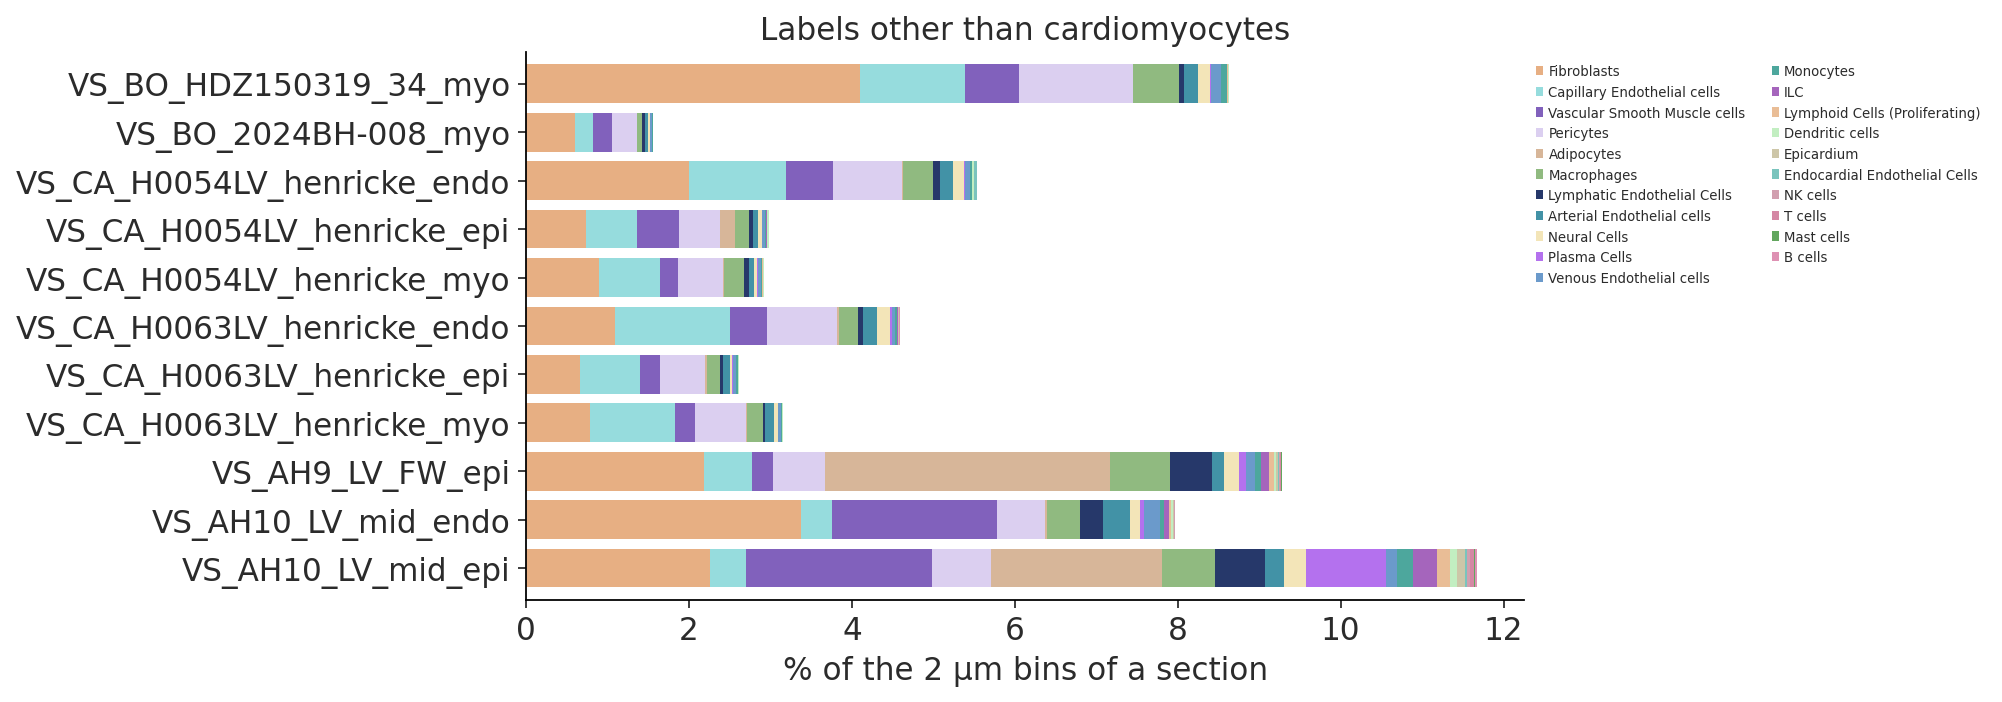

In [37]:
others = labels_after.drop(index=cardiomyocytes)
largest_first = others.sum(axis=1).sort_values(ascending=False).index
share = (100 * others.loc[largest_first] / per_section_after).T
colours = [style.CT[label] for label in share.columns]
ax = share.plot.barh(stacked=True, color=colours, width=0.8, figsize=(8, 4.5))
ax.invert_yaxis()
ax.set(xlabel="% of the 2 µm bins of a section", title="Labels other than cardiomyocytes")
ax.legend(fontsize=6, ncol=2, bbox_to_anchor=(1.0, 1.0), loc="upper left")
plt.show()

How much does the clean-up remove on each section, and by which flag? The pipeline writes a summary per section.

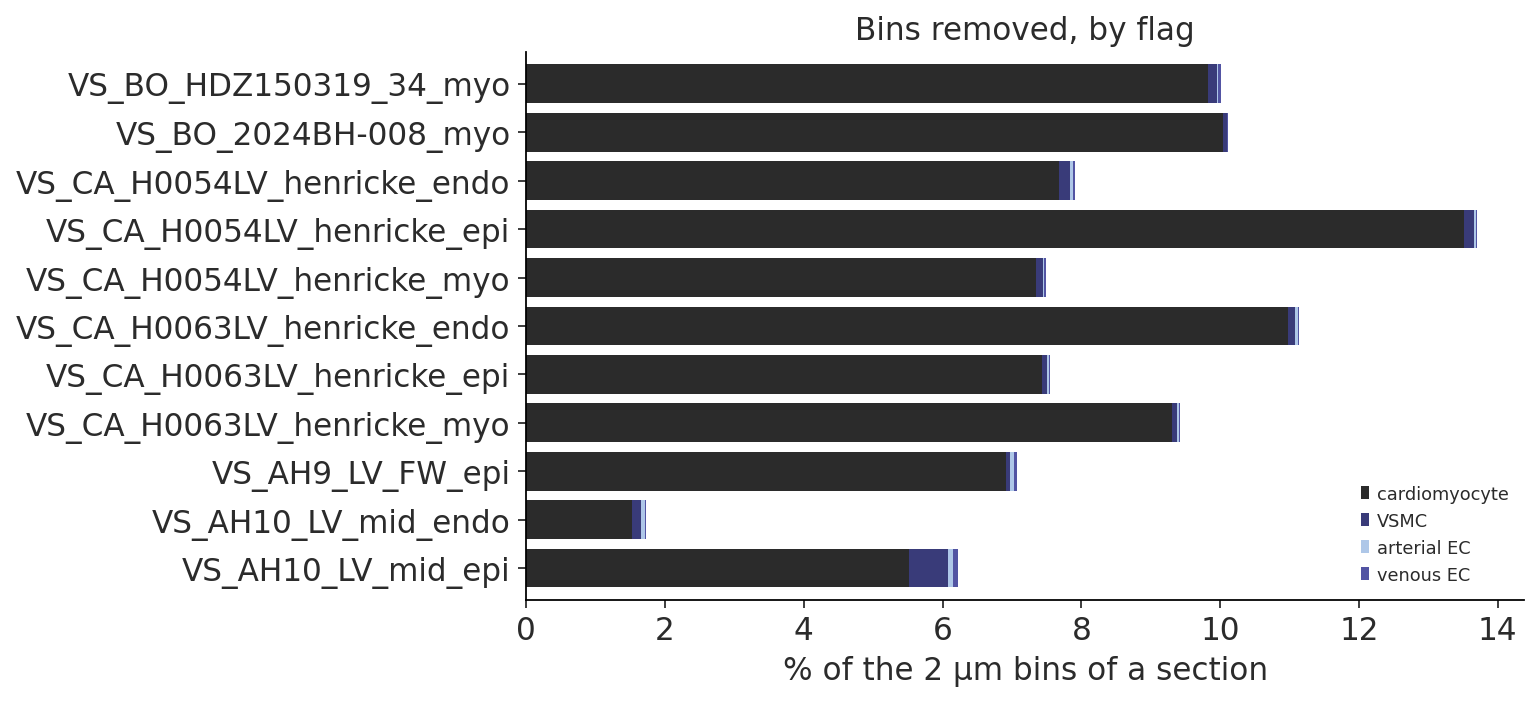

cardiomyocyte    97.62
VSMC              1.65
arterial EC       0.41
venous EC         0.33


In [38]:
summary_by_section = {}
for name in all_sections:
    summary_by_section[name] = pd.read_json(section_path(cfg, "clean_summary", name), typ="series")
summaries = pd.DataFrame(summary_by_section).T
summaries = summaries.drop(columns="slide").astype(float)
flag_columns = [f"n_{flag}" for flag in SPILLOVER_FLAGS]
flag_names = [style.SPILLOVER_LABELS[flag] for flag in SPILLOVER_FLAGS]
flag_colours = [style.SPILLOVER[flag] for flag in SPILLOVER_FLAGS]
by_flag = 100 * summaries[flag_columns].div(summaries["n_2um"], axis=0)
by_flag.columns = flag_names
ax = by_flag.plot.barh(stacked=True, color=flag_colours, width=0.8, figsize=(8, 4.5))
ax.invert_yaxis()
ax.set(xlabel="% of the 2 µm bins of a section", title="Bins removed, by flag")
ax.legend(title="", fontsize=8, loc="lower right")
plt.show()
removed_by_flag = summaries[flag_columns].sum()
share_by_flag = 100 * removed_by_flag / summaries["n_2um_flagged"].sum()
share_by_flag.index = flag_names
print(share_by_flag.round(2).to_string())

And which labels does it touch over all sections?

In [39]:
per_label_before = labels_before.sum(axis=1)
per_label_after = labels_after.sum(axis=1)
removed_by_label = pd.DataFrame(
    {
        "bins": per_label_before,
        "after the clean-up": per_label_after,
        "% removed": 100 * (1 - per_label_after / per_label_before),
    }
)
removed_by_label = removed_by_label.sort_values("% removed", ascending=False)
removed_by_label.round(2).head(7)

,bins,after the clean-up,% removed
L3_label,,,
Venous Endothelial cells,66978,49274,26.43
Arterial Endothelial cells,115591,93053,19.50
Atrial Cardiomyocytes,22144,18338,17.19
Vascular Smooth Muscle cells,548912,455674,16.99
Ventricular Cardiomyocytes,69010790,63028198,8.67
Fibroblasts,1061506,1058978,0.24
Capillary Endothelial cells,531622,530414,0.23


Last, we return to the question of trust. On the eight Berlin sections every decode pixel has the marker support
from the certainty score: does its neighbourhood hold marker transcripts of the type it is called? We compare
the pixels that the flags remove with those that stay, together with the number of transcripts in their 3 × 3
neighbourhood.

In [40]:
min_removed = 1000  # the table shows the cell types with more removed pixels than this
support_by_section = []
for name in scored_sections:
    section_features = features[name]
    is_removed = pd.read_parquet(section_path(cfg, "flags", name), columns=SPILLOVER_FLAGS).any(axis=1)
    table = pd.DataFrame(
        {
            "cell type": pd.Categorical.from_codes(section_features["k1"], categories=factor_order),
            "supported": section_features["marker_support"],
            "umi": section_features["local_umi"].astype(float),
            "state": np.where(is_removed, "removed", "kept"),
        }
    )
    support_by_section.append(table.groupby(["cell type", "state"], observed=True).agg(["sum", "size"]))
support = pd.concat(support_by_section).groupby(level=["cell type", "state"], observed=True).sum()
pixel_counts = support["supported", "size"]
marker_support = pd.concat(
    {
        "pixels": pixel_counts.unstack("state"),
        "marker support (%)": (100 * support["supported", "sum"] / pixel_counts).unstack("state"),
        "transcripts in the neighbourhood": (support["umi", "sum"] / pixel_counts).unstack("state"),
    },
    axis=1,
)
many_removed = marker_support[marker_support["pixels", "removed"] > min_removed]
many_removed.sort_values(("pixels", "removed"), ascending=False).round(1)

pixels            marker support (%)  \
state                               kept    removed               kept   
cell type                                                                
Ventricular Cardiomyocytes    67676623.0  6929141.0               98.1   
Vascular Smooth Muscle cells    263909.0    66703.0               87.6   
Arterial Endothelial cells       71830.0    15959.0               95.3   
Venous Endothelial cells         32619.0    14756.0               88.9   
Fibroblasts                     866049.0     2104.0               94.1   
Atrial Cardiomyocytes            12877.0     1039.0               72.8   

                                     transcripts in the neighbourhood          
state                        removed                             kept removed  
cell type                                                                      
Ventricular Cardiomyocytes      99.0                            125.3   102.5  
Vascular Smooth Muscle cells    86.6                            130.3    98.0  
Arterial Endothelial cells      95.5                            190.9   150.6  
Venous Endothelial cells        86.0                            142.0   102.3  
Fibroblasts                     95.1                            145.1    91.4  
Atrial Cardiomyocytes           83.9                             82.3    47.7

Over the 11 sections the clean-up takes 72,683,834 bins to 66,558,914. A section loses between 1.72% (AH10
endo) and 13.70% (H0054 epi) of its bins, and 97.62% of the removed bins carry the cardiomyocyte flag. Venous
endothelium loses 26.43% of its bins, arterial endothelium 19.50%, smooth muscle 16.99% and ventricular
cardiomyocytes 8.67%; fibroblasts, the next label, lose 0.24%. The removed pixels have marker support as often as
the kept ones (99.0% against 98.1% for ventricular cardiomyocytes, 86.6% against 87.6% for smooth muscle) but
fewer transcripts around them (102.5 against 125.3, and 98.0 against 130.3).

## Key takeaways

- With a fixed atlas model, FICTURE calls 98.9% of the decode pixels of a section with a posterior above 0.99, so
  the posterior cannot rank the calls; a certainty score built from depth, marker share, neighbour agreement and
  margin can.
- A single threshold of 0.37 reaches a precision of 99% at a coverage of 94.6%, but keeps as little as 5.3% of
  the pixels of a rare type; thresholds per type between 0.20 and 0.41, applied in layers, keep all 23 types.
- The 2 µm `AnnData` keeps the most probable type of every bin together with its certainty score; 99.96% of the
  decoded bins are matched to Space Ranger bins.
- Transcripts in whitespace are found on the registered H&E. The four spillover flags, and only these, remove
  between 1.72% and 13.70% of the 2 µm bins of a section; 97.62% of the removed bins are cardiomyocyte spillover.
- The removed bins are well supported by markers but lie in empty space: only the histology separates them from
  cells.
- Every step is one function of `hhca.tl`; the scripts in `scripts/substrate/` call the same functions on all
  sections.